# UTS Data Mining
##Klasifikasi Kualitas Anggur (Wine Quality)

Nama : Kirana Aripuspa Wardani

NIM  : 2404010010


## Tujuan
Membuat model klasifikasi untuk memprediksi kualitas anggur (quality) berdasarkan sifat kimiawinya menggunakan data training, kemudian menerapkan model tersebut pada data testing.

## 1. Persiapan Data
Pada tahap ini library yang dibutuhkan di-import, lalu data training dan data testing dibaca menggunakan pandas. Data training berisi fitur kimiawi beserta label quality, sedangkan data testing hanya berisi fitur kimiawi tanpa label quality.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("data_training.csv")
test = pd.read_csv("data_testing.csv")

print("Ukuran data training:", train.shape)
print("Ukuran data testing :", test.shape)
train.head()

Ukuran data training: (857, 13)
Ukuran data testing : (286, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.3,0.740,0.08,1.7,0.094,10.0,45.0,0.99576,3.24,0.50,9.8,5,1366
1,8.1,0.575,0.22,2.1,0.077,12.0,65.0,0.99670,3.29,0.51,9.2,5,103
2,10.1,0.430,0.40,2.6,0.092,13.0,52.0,0.99834,3.22,0.64,10.0,7,942
3,12.9,0.500,0.55,2.8,0.072,7.0,24.0,1.00012,3.09,0.68,10.9,6,811
4,8.4,0.360,0.32,2.2,0.081,32.0,79.0,0.99640,3.30,0.72,11.0,6,918


**Interpretasi:**

Data training terdiri dari 857 baris dan 13 kolom, sedangkan data testing terdiri dari 286 baris dan 12 kolom. Selisih satu kolom terjadi karena data testing tidak memiliki kolom quality. Data berisi 11 fitur kimiawi anggur (fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, dan alcohol), kolom Id sebagai pengenal data, dan quality sebagai target. Seluruh fitur bertipe numerik sehingga dapat langsung diolah tanpa proses encoding.

## 2. Pembersihan Data
Model tidak dapat dilatih jika terdapat nilai yang hilang (missing values), sehingga dilakukan pengecekan missing values pada kedua dataset. Dilakukan juga pengecekan data duplikat serta ringkasan statistik untuk melihat apakah rentang nilai antar fitur sangat bervariasi, yang menentukan perlu tidaknya feature scaling.

In [27]:
print("Missing values data training:")
print(train.isnull().sum())
print()
print("Total missing values data testing:", test.isnull().sum().sum())
print("Jumlah data duplikat (training):", train.duplicated().sum())
print()
train.describe().T

Missing values data training:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

Total missing values data testing: 0
Jumlah data duplikat (training): 0



,count,mean,std,min,25%,50%,75%,max
fixed acidity,857.0,8.261960,1.701992,4.60000,7.10000,7.90000,9.1000,15.6000
volatile acidity,857.0,0.529393,0.179162,0.12000,0.39500,0.52000,0.6400,1.5800
citric acid,857.0,0.267351,0.195144,0.00000,0.09000,0.25000,0.4200,1.0000
residual sugar,857.0,2.506184,1.293512,0.90000,1.90000,2.20000,2.6000,15.5000
chlorides,857.0,0.086830,0.048721,0.01200,0.07000,0.07900,0.0900,0.6110
free sulfur dioxide,857.0,15.782964,10.300402,1.00000,7.00000,14.00000,21.0000,68.0000
total sulfur dioxide,857.0,45.978413,31.692113,6.00000,21.00000,38.00000,63.0000,278.0000
density,857.0,0.996692,0.001901,0.99007,0.99552,0.99668,0.9978,1.0032
pH,857.0,3.313092,0.152079,2.74000,3.21000,3.31000,3.4000,4.0100
sulphates,857.0,0.656709,0.167364,0.39000,0.55000,0.62000,0.7300,2.0000


**Interpretasi:**

Tidak ditemukan missing values pada data training maupun data testing, dan tidak ada data duplikat, sehingga tidak diperlukan imputasi maupun penghapusan data. Dari ringkasan statistik terlihat rentang nilai antar fitur sangat berbeda. Contohnya total sulfur dioxide berkisar antara 6 sampai 278, sedangkan chlorides hanya berkisar antara 0,012 sampai 0,611. Perbedaan skala ini dapat membuat fitur dengan angka besar mendominasi perhitungan pada beberapa algoritma, sehingga feature scaling perlu dilakukan.

## 3. Eksplorasi Distribusi Target (Quality)
Distribusi variabel target dilihat untuk mengetahui apakah jumlah data di setiap kelas seimbang. Distribusi kelas memengaruhi kemampuan model dalam memprediksi masing-masing kelas.

quality
3      6
4     26
5    362
6    341
7    109
8     13
Name: count, dtype: int64


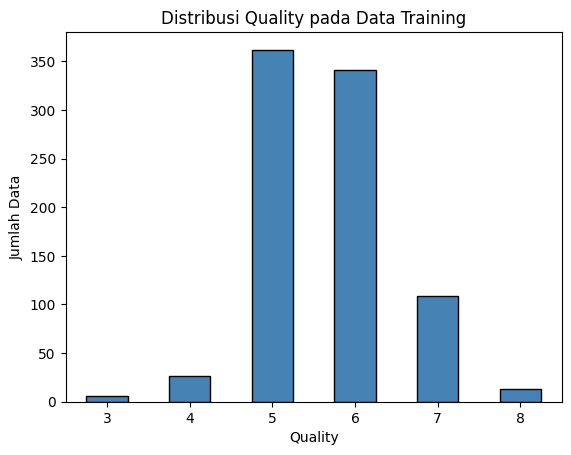

In [28]:
dist = train["quality"].value_counts().sort_index()
print(dist)

dist.plot(kind="bar", color="steelblue", edgecolor="black")
plt.title("Distribusi Quality pada Data Training")
plt.xlabel("Quality")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=0)
plt.show()

**Interpretasi:**

Distribusi quality tidak seimbang. Mayoritas anggur memiliki quality 5 (362 data) dan 6 (341 data), diikuti quality 7 (109 data). Sementara itu kelas ekstrem sangat sedikit, yaitu quality 3 hanya 6 data, quality 4 sebanyak 26 data, dan quality 8 sebanyak 13 data. Nilai quality pada data berkisar 3 sampai 8. Ketidakseimbangan ini membuat model cenderung lebih mudah memprediksi kelas 5 dan 6 dibandingkan kelas yang jumlah datanya sedikit.

## 4. Pemisahan Fitur dan Target serta Pembagian Data Latih dan Validasi
Variabel quality dijadikan target (y), sedangkan 11 variabel kimiawi dijadikan fitur (X). Kolom Id tidak digunakan sebagai fitur karena hanya berfungsi sebagai pengenal data dan tidak berhubungan dengan kualitas anggur.

Data training kemudian dibagi menjadi 80% data latih dan 20% data validasi (dengan stratify agar proporsi kelas tetap terjaga). Pembagian dilakukan sebelum scaling agar informasi dari data validasi tidak ikut digunakan saat menghitung parameter scaling (mencegah data leakage).

In [30]:
from sklearn.model_selection import train_test_split

X = train.drop(columns=["quality", "Id"])
y = train["quality"]

X_test = test.drop(columns=["Id"])
id_test = test["Id"]

X_tr, X_val, y_tr, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Jumlah fitur:", X.shape[1])
print("Data latih   :", X_tr.shape)
print("Data validasi:", X_val.shape)

Jumlah fitur: 11
Data latih   : (685, 11)
Data validasi: (172, 11)


**Interpretasi:**

Terdapat 11 fitur yang digunakan. Data training dibagi menjadi 685 data latih dan 172 data validasi. Dengan stratify, proporsi setiap kelas quality pada data latih dan validasi tetap sama dengan data aslinya.

## 5. Feature Scaling, Pembuatan Model, dan Evaluasi
Karena rentang nilai antar fitur sangat berbeda, dilakukan feature scaling menggunakan StandardScaler yang mengubah setiap fitur sehingga memiliki rata-rata 0 dan standar deviasi 1. Scaler hanya dilatih (fit) pada data latih, kemudian diterapkan (transform) ke data validasi agar evaluasi tidak terpengaruh informasi dari data validasi.

Dua algoritma klasifikasi dibandingkan:
- **Random Forest**: gabungan banyak pohon keputusan yang hasil prediksinya divoting, sehingga lebih stabil dan mampu menangkap hubungan non-linear.
- **K-Nearest Neighbors (KNN)**: memprediksi kelas berdasarkan mayoritas kelas dari k tetangga terdekat.

Metrik evaluasi yang digunakan adalah akurasi dan confusion matrix.

In [31]:
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_tr)   # fit hanya pada data latih
X_val_scaled = scaler.transform(X_val)     # validasi hanya di-transform

print("Rata-rata data latih setelah scaling:", X_tr_scaled.mean(axis=0).round(2))
print("Std data latih setelah scaling      :", X_tr_scaled.std(axis=0).round(2))
print()

models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
}

hasil_akurasi = {}
for nama, m in models.items():
    m.fit(X_tr_scaled, y_tr)
    akurasi = accuracy_score(y_val, m.predict(X_val_scaled))
    hasil_akurasi[nama] = akurasi
    print(f"{nama:15s} akurasi validasi: {akurasi:.4f}")

Rata-rata data latih setelah scaling: [-0. -0. -0.  0.  0.  0.  0.  0. -0. -0.  0.]
Std data latih setelah scaling      : [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Random Forest   akurasi validasi: 0.6047
KNN             akurasi validasi: 0.4826


**Interpretasi:**

Setelah scaling, seluruh fitur pada data latih memiliki rata-rata mendekati 0 dan standar deviasi 1, sehingga berada pada skala yang sebanding. Akurasi Random Forest pada data validasi sebesar 60,47%, sedangkan KNN sebesar 48,26%. Random Forest unggul sekitar 12 poin persentase sehingga dipilih sebagai model akhir. Random Forest lebih baik karena mampu menangkap hubungan non-linear antar fitur dan lebih tahan terhadap outlier, sedangkan KNN sensitif terhadap distribusi kelas yang tidak seimbang karena tetangga terdekat cenderung berasal dari kelas mayoritas.

## 6. Evaluasi Detail Model Random Forest
Confusion matrix dan classification report digunakan untuk melihat kelas mana yang berhasil dan gagal diprediksi oleh model. Selain itu dilihat feature importance untuk mengetahui fitur kimiawi yang paling berpengaruh terhadap kualitas anggur.

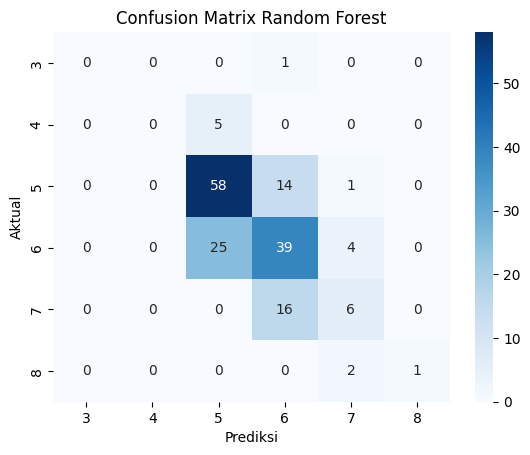

              precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00         5
           5       0.66      0.79      0.72        73
           6       0.56      0.57      0.57        68
           7       0.46      0.27      0.34        22
           8       1.00      0.33      0.50         3

    accuracy                           0.60       172
   macro avg       0.45      0.33      0.35       172
weighted avg       0.58      0.60      0.58       172



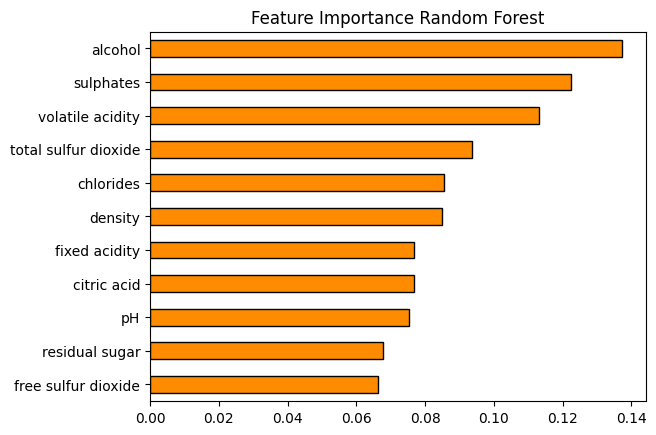

alcohol                 0.137
sulphates               0.123
volatile acidity        0.113
total sulfur dioxide    0.094
chlorides               0.086
density                 0.085
fixed acidity           0.077
citric acid             0.077
pH                      0.075
residual sugar          0.068
free sulfur dioxide     0.066
dtype: float64


In [32]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

best = models["Random Forest"]
pred = best.predict(X_val_scaled)
kelas = sorted(y.unique())

cm = confusion_matrix(y_val, pred, labels=kelas)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=kelas, yticklabels=kelas)
plt.title("Confusion Matrix Random Forest")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.show()

print(classification_report(y_val, pred, zero_division=0))

imp = pd.Series(best.feature_importances_, index=X.columns).sort_values(ascending=False)
imp.sort_values().plot(kind="barh", color="darkorange", edgecolor="black")
plt.title("Feature Importance Random Forest")
plt.show()
print(imp.round(3))

**Interpretasi:**

Akurasi keseluruhan model sebesar 0,60. Model paling baik memprediksi quality 5 (58 dari 73 data benar, f1-score 0,72) dan quality 6 (39 dari 68 data benar, f1-score 0,57), yaitu dua kelas dengan data terbanyak. Quality 7 kurang baik (recall 0,27) karena 16 dari 22 datanya diprediksi sebagai quality 6. Quality 3 dan 4 sama sekali tidak berhasil diprediksi (f1-score 0,00) karena datanya sangat sedikit, sedangkan quality 8 hanya 1 dari 3 data yang benar sehingga hasilnya kurang dapat diandalkan. Kesalahan pada kelas mayoritas umumnya terjadi antar kelas bersebelahan (5 dengan 6, dan 6 dengan 7) karena perbedaan sifat kimiawinya tipis. Macro avg f1-score (0,35) yang jauh di bawah weighted avg f1-score (0,58) menunjukkan model baik pada kelas mayoritas tetapi lemah pada kelas minoritas akibat distribusi quality yang tidak seimbang.

Fitur yang paling berpengaruh adalah alcohol (0,137), sulphates (0,123), dan volatile acidity (0,113), sedangkan yang paling kecil adalah residual sugar (0,068) dan free sulfur dioxide (0,066). Artinya model paling banyak memanfaatkan informasi kadar alkohol, sulfat, dan keasaman volatil dalam menentukan kualitas anggur.

## 7. Pelatihan Ulang dan Penyimpanan Model
Setelah Random Forest dipilih sebagai model terbaik, scaler dan model dilatih ulang menggunakan seluruh data training (100%) agar mempelajari data sebanyak mungkin. Pada tahap ini tidak ada lagi evaluasi, sehingga penggunaan seluruh data training untuk scaling tidak menimbulkan kebocoran. Model dan scaler kemudian disimpan ke dalam file .pkl menggunakan joblib sehingga dapat digunakan kembali tanpa melatih ulang.

In [33]:
import joblib

final_scaler = StandardScaler()
X_scaled = final_scaler.fit_transform(X)

final_model = RandomForestClassifier(n_estimators=300, random_state=42)
final_model.fit(X_scaled, y)

joblib.dump(final_model, "model_wine.pkl")
joblib.dump(final_scaler, "scaler_wine.pkl")

print("Model dan scaler berhasil disimpan.")

Model dan scaler berhasil disimpan.


**Interpretasi:**

Scaler dan model Random Forest telah dilatih ulang pada seluruh data training (857 data), kemudian disimpan dalam file model_wine.pkl dan scaler_wine.pkl. Scaler perlu disimpan karena data baru harus diskala dengan parameter yang sama seperti data training sebelum diprediksi.

## 8. Prediksi Data Testing (Deployment Model)
Model dan scaler yang sudah disimpan dimuat kembali, kemudian digunakan untuk memprediksi quality pada data testing. Hasil prediksi disimpan dalam file CSV yang hanya berisi dua kolom, yaitu Id dan Quality, dengan pemisah titik koma (;) sesuai format template dari dosen. Nama file mengikuti format hasilprediksi_010.csv.

In [34]:
model_dep = joblib.load("model_wine.pkl")
scaler_dep = joblib.load("scaler_wine.pkl")

X_test_dep = scaler_dep.transform(X_test)
hasil = model_dep.predict(X_test_dep)

submission = pd.DataFrame({"Id": id_test, "Quality": hasil})

nama_file = "hasilprediksi_010.csv"
submission.to_csv(nama_file, index=False, sep=";")

print("Ukuran hasil prediksi:", submission.shape)
print()
print("Distribusi hasil prediksi:")
print(submission["Quality"].value_counts().sort_index())
submission.head()

Ukuran hasil prediksi: (286, 2)

Distribusi hasil prediksi:
Quality
5    132
6    125
7     29
Name: count, dtype: int64


,Id,Quality
0,222,5
1,1514,6
2,417,5
3,754,5
4,516,5


**Interpretasi:**

Prediksi berhasil dibuat untuk 286 data testing. File hasil hanya berisi dua kolom (Id dan Quality) dengan jumlah baris sama dengan data testing. Hasil prediksi terdiri dari quality 5 sebanyak 132 data, quality 6 sebanyak 125 data, dan quality 7 sebanyak 29 data. Model tidak memprediksi quality 3, 4, maupun 8, sejalan dengan hasil evaluasi sebelumnya bahwa model kesulitan mengenali kelas dengan data sedikit dan cenderung memprediksi kelas mayoritas. Proporsi hasil prediksi (5 dan 6 dominan, diikuti 7) mirip dengan distribusi quality pada data training.

## 9. Verifikasi Format File Hasil
Sebelum dikumpulkan, file hasil prediksi dicocokkan dengan template untuk memastikan nama kolom, jumlah baris, dan urutan Id sudah sesuai.

In [35]:
cek = pd.read_csv(nama_file, sep=";")
tpl = pd.read_csv("hasilprediksi_3digitNIMterakhir.csv", sep=";")

print("Nama kolom sama dengan template :", cek.columns.tolist() == tpl.columns.tolist())
print("Jumlah baris sama               :", len(cek) == len(tpl))
print("Urutan Id sama dengan template  :", (cek["Id"].values == tpl["Id"].values).all())
print("Ada nilai kosong                :", cek.isnull().any().any())

Nama kolom sama dengan template : True
Jumlah baris sama               : True
Urutan Id sama dengan template  : True
Ada nilai kosong                : False


**Interpretasi:**

Seluruh pengecekan menunjukkan hasil yang sesuai: nama kolom dan urutan Id sama dengan template, jumlah baris sama, dan tidak ada nilai kosong.

## 10. Kesimpulan
1. Data training dan testing bersih (tanpa missing values maupun duplikat), tetapi rentang antar fitur berbeda jauh sehingga dilakukan scaling dengan StandardScaler yang dilatih hanya pada data latih untuk menghindari data leakage.
2. Distribusi quality tidak seimbang, dengan mayoritas data pada quality 5 dan 6.
3. Dari dua model yang dibandingkan, Random Forest (akurasi validasi 60,47%) lebih baik daripada KNN (48,26%) sehingga dipilih sebagai model akhir.
4. Fitur yang paling berpengaruh terhadap kualitas anggur adalah alcohol, sulphates, dan volatile acidity.
5. Model sulit memprediksi kelas dengan data sedikit (quality 3, 4, dan 8) akibat ketidakseimbangan kelas.
6. Model telah disimpan dan digunakan untuk memprediksi 286 data testing. Hasil prediksi hanya mencakup quality 5, 6, dan 7, dengan hasil disimpan sesuai format yang diminta.

In [36]:
from google.colab import files
files.download(nama_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>